# EDA on Retail Sales Data
**Fouzia Khan** | Data Analytics Intern | Oasis Infobyte (OIBSIP)

Objective: explore retail sales data to find sales patterns, customer behaviour and business recommendations. Amounts are shown with a dollar sign for display only (the currency is not stated in the data).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os

sns.set_theme(style="whitegrid", font_scale=1.05)
PRIMARY, ACCENT = "#2F6F8F", "#E07A5F"
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 14})
money = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")

os.makedirs("charts", exist_ok=True)
def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load and Inspect

In [2]:
PATH = "/content/drive/MyDrive/retail_sales_dataset.csv"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PATH = "retail_sales_dataset.csv"

df = pd.read_csv(PATH, parse_dates=["Date"])
print("Shape:", df.shape)
print(df.dtypes)

Mounted at /content/drive
Shape: (1000, 9)
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Quantity x Price == Total Amount:", (df["Quantity"] * df["Price per Unit"] == df["Total Amount"]).all())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64
Duplicate rows: 0
Quantity x Price == Total Amount: True


The data has 1,000 rows and 9 columns, with no nulls or duplicates. Every row satisfies Quantity × Price = Total Amount. Only one day of January 2024 exists, so that month is left out of the trend charts.

## 2. Descriptive Statistics

In [5]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
stats = df[num_cols].agg(["mean", "median", "std"]).T
stats["mode"] = [df[c].mode().iloc[0] for c in num_cols]
stats[["mean", "median", "mode", "std"]].round(2)

,mean,median,mode,std
Age,41.39,42.0,43,13.68
Quantity,2.51,3.0,4,1.13
Price per Unit,179.89,50.0,50,189.68
Total Amount,456.00,135.0,50,560.00


Total revenue is \$456,000. The median sale (\$135) is far below the mean (\$456) and the std (\$560) is larger than the mean, so a few large orders lift the average.

## 3. Time Series Analysis

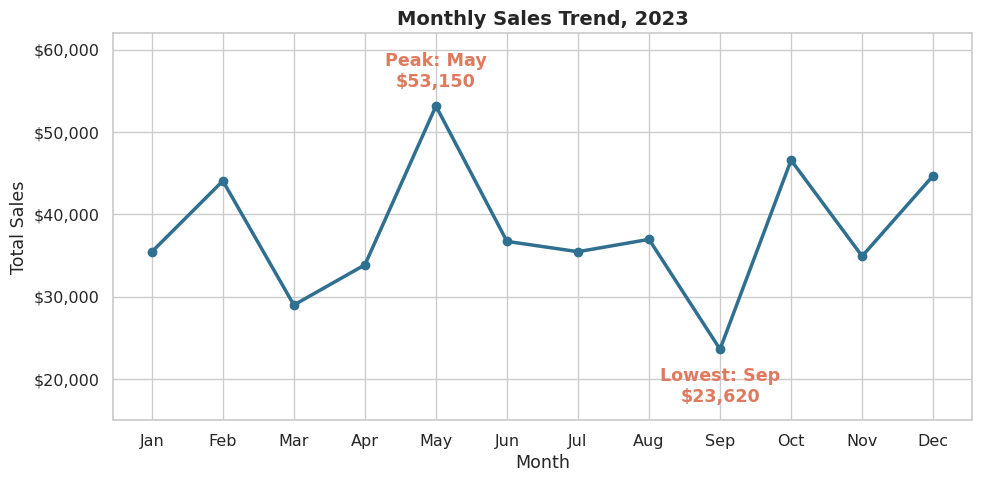

In [6]:
sales = df.set_index("Date")["Total Amount"]
sales = sales[sales.index < "2024-01-01"]
monthly = sales.resample("ME").sum()
quarterly = sales.resample("QE").sum()
monthly.index = monthly.index.strftime("%b")
quarterly.index = ["Q1", "Q2", "Q3", "Q4"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index, monthly.values, marker="o", color=PRIMARY, linewidth=2.5)
hi, lo = monthly.idxmax(), monthly.idxmin()
ax.annotate(f"Peak: {hi}\n${monthly.max():,}", (hi, monthly.max()), xytext=(0, 14),
            textcoords="offset points", ha="center", color=ACCENT, fontweight="bold")
ax.annotate(f"Lowest: {lo}\n${monthly.min():,}", (lo, monthly.min()), xytext=(0, -38),
            textcoords="offset points", ha="center", color=ACCENT, fontweight="bold")
ax.set_title("Monthly Sales Trend, 2023"); ax.set_xlabel("Month"); ax.set_ylabel("Total Sales")
ax.yaxis.set_major_formatter(money); ax.set_ylim(15000, 62000)
save("01_monthly_sales_trend")

May is the peak month (\$53,150) and September the lowest (\$23,620), less than half of May.

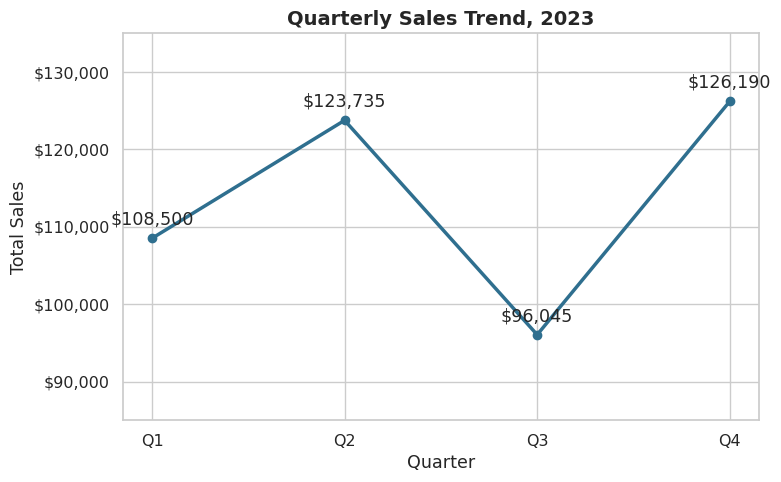

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(quarterly.index, quarterly.values, marker="o", color=PRIMARY, linewidth=2.5)
for q, v in quarterly.items():
    ax.annotate(f"${v:,}", (q, v), xytext=(0, 10), textcoords="offset points", ha="center")
ax.set_title("Quarterly Sales Trend, 2023"); ax.set_xlabel("Quarter"); ax.set_ylabel("Total Sales")
ax.yaxis.set_major_formatter(money); ax.set_ylim(85000, 135000)
save("02_quarterly_sales_trend")

Q4 is the strongest quarter (\$126,190) and Q3 the weakest (\$96,045), about 24% lower.

## 4. Customer Demographics

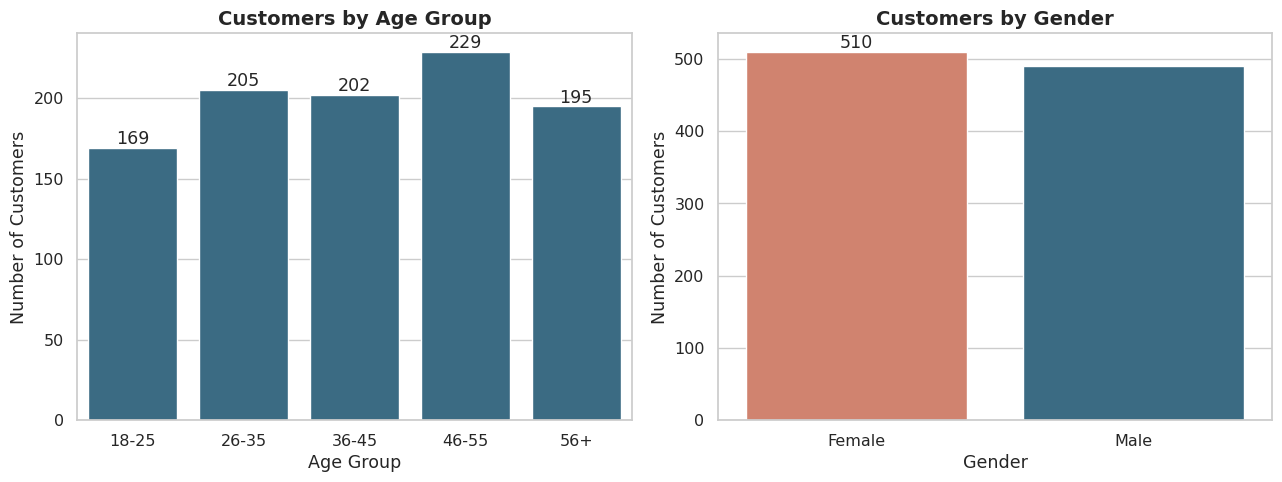

In [8]:
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
age_counts = df["Age Group"].value_counts().sort_index()
sns.barplot(x=age_counts.index, y=age_counts.values, color=PRIMARY, ax=axes[0])
axes[0].set_title("Customers by Age Group"); axes[0].set_xlabel("Age Group"); axes[0].set_ylabel("Number of Customers")
axes[0].bar_label(axes[0].containers[0])

gender_counts = df["Gender"].value_counts()
sns.barplot(x=gender_counts.index, y=gender_counts.values, palette=[ACCENT, PRIMARY], hue=gender_counts.index, legend=False, ax=axes[1])
axes[1].set_title("Customers by Gender"); axes[1].set_xlabel("Gender"); axes[1].set_ylabel("Number of Customers")
axes[1].bar_label(axes[1].containers[0])
save("03_age_gender_distribution")

Customers are spread evenly across ages (largest group 46-55 with 229, smallest 18-25 with 169). Gender is balanced: 510 female (51%) and 490 male (49%).

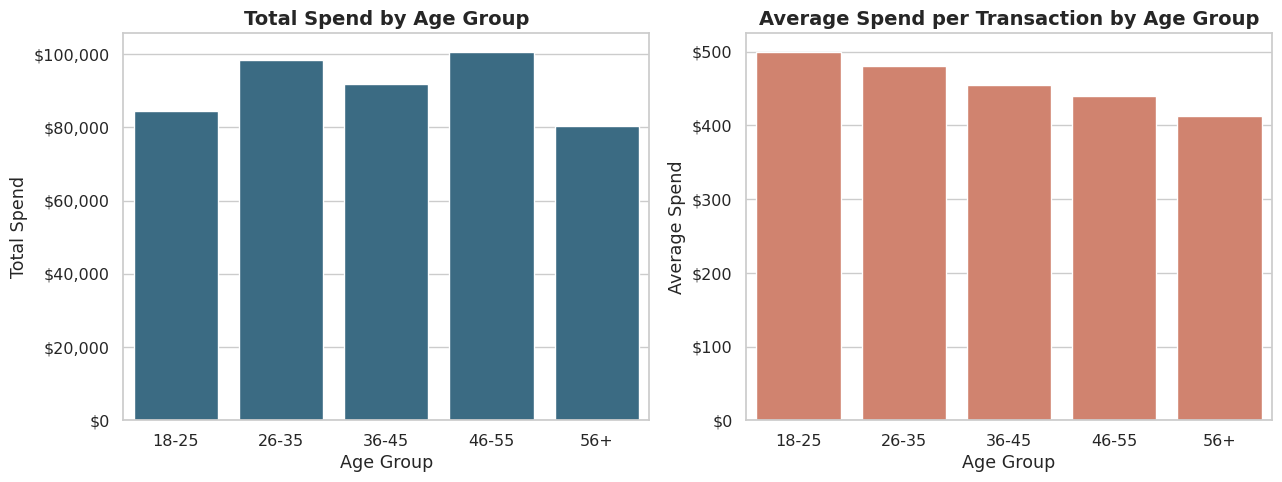

,sum,mean
Gender,,
Female,232840,456.55
Male,223160,455.43


In [9]:
age_spend = df.groupby("Age Group", observed=True)["Total Amount"].agg(["sum", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=age_spend.index, y=age_spend["sum"], color=PRIMARY, ax=axes[0])
axes[0].set_title("Total Spend by Age Group"); axes[0].set_xlabel("Age Group"); axes[0].set_ylabel("Total Spend")
axes[0].yaxis.set_major_formatter(money)
sns.barplot(x=age_spend.index, y=age_spend["mean"], color=ACCENT, ax=axes[1])
axes[1].set_title("Average Spend per Transaction by Age Group"); axes[1].set_xlabel("Age Group"); axes[1].set_ylabel("Average Spend")
axes[1].yaxis.set_major_formatter(money)
save("04_spend_by_age_group")

df.groupby("Gender")["Total Amount"].agg(["sum", "mean"]).round(2)

Ages 46-55 spend the most in total (\$100,690) because they are the largest group, but 18-25 spend the most per transaction (\$500.30). Average spend falls with age, down to \$412.36 for 56+. Men and women spend almost the same per transaction (\$455.43 vs \$456.55).

## 5. Product Analysis

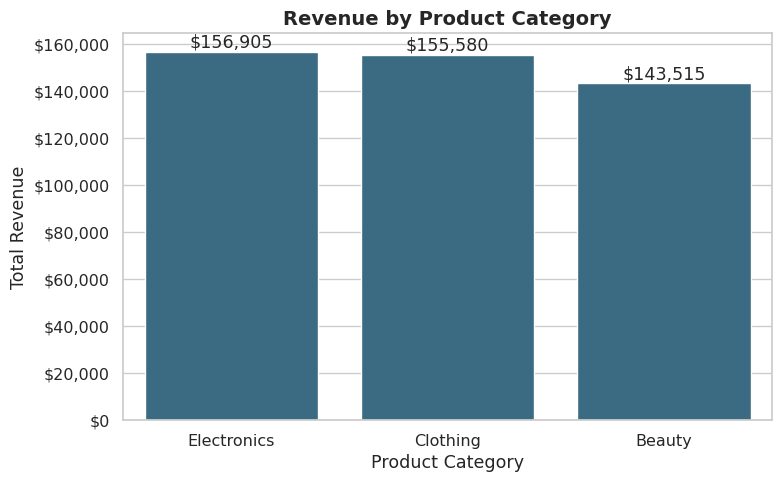

,Revenue,Units,Transactions,Revenue Share %
Product Category,,,,
Electronics,156905,849,342,34.4
Clothing,155580,894,351,34.1
Beauty,143515,771,307,31.5


In [10]:
cat = df.groupby("Product Category").agg(Revenue=("Total Amount", "sum"),
                                         Units=("Quantity", "sum"),
                                         Transactions=("Transaction ID", "count")).sort_values("Revenue", ascending=False)
cat["Revenue Share %"] = (cat["Revenue"] / cat["Revenue"].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=cat.index, y=cat["Revenue"], color=PRIMARY, ax=ax)
ax.set_title("Revenue by Product Category"); ax.set_xlabel("Product Category"); ax.set_ylabel("Total Revenue")
ax.yaxis.set_major_formatter(money)
ax.bar_label(ax.containers[0], labels=[f"${v:,}" for v in cat["Revenue"]])
save("05_revenue_by_category")
cat

Revenue is close across categories: Electronics \$156,905 (34.4%), Clothing \$155,580 (34.1%), Beauty \$143,515 (31.5%).

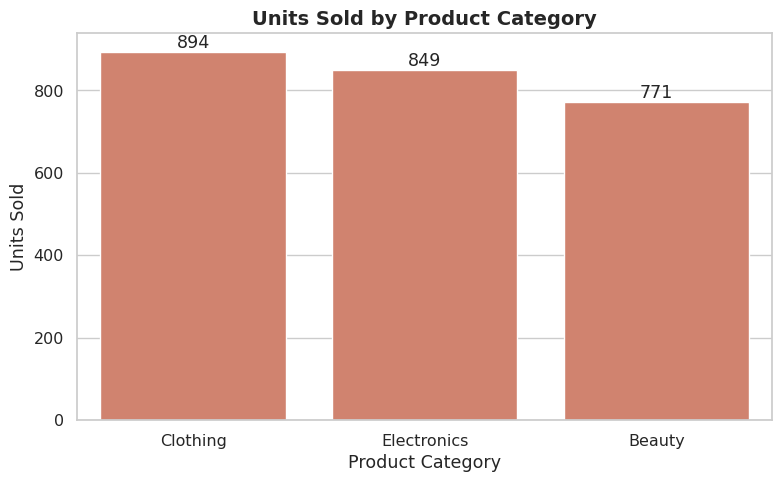

In [11]:
cat_units = cat.sort_values("Units", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=cat_units.index, y=cat_units["Units"], color=ACCENT, ax=ax)
ax.set_title("Units Sold by Product Category"); ax.set_xlabel("Product Category"); ax.set_ylabel("Units Sold")
ax.bar_label(ax.containers[0])
save("06_units_by_category")

Clothing sells the most units (894), then Electronics (849) and Beauty (771).

**Top 10 products:** the dataset has no product names, so the closest valid substitute is Product Category × Price per Unit.

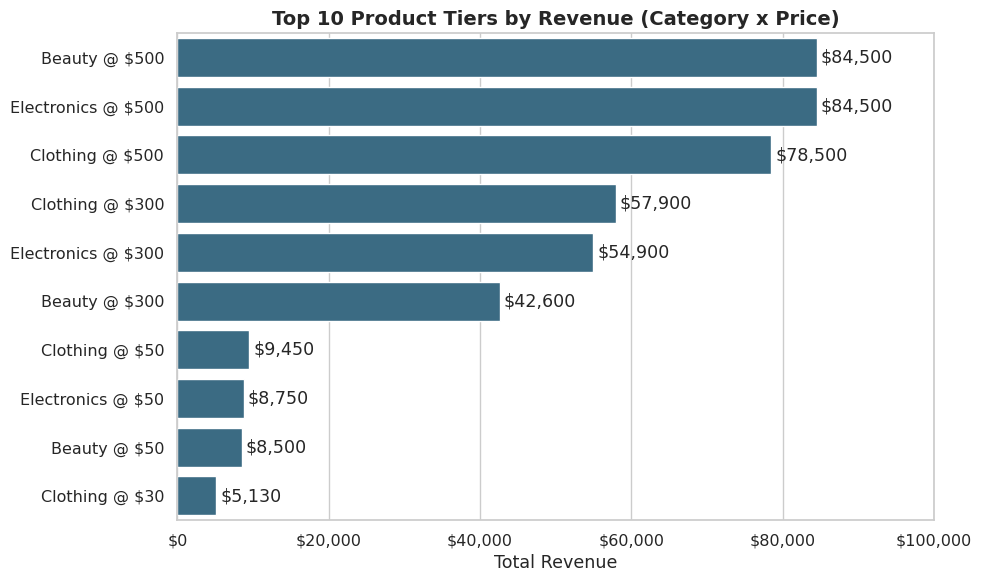

$300/$500 items: 39.6% of transactions, 88.4% of revenue


In [12]:
top10 = (df.groupby(["Product Category", "Price per Unit"])
           .agg(Revenue=("Total Amount", "sum"), Units=("Quantity", "sum"))
           .sort_values("Revenue", ascending=False).head(10).reset_index())
top10["Product Tier"] = top10["Product Category"] + " @ $" + top10["Price per Unit"].astype(str)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top10, y="Product Tier", x="Revenue", color=PRIMARY, ax=ax)
ax.set_title("Top 10 Product Tiers by Revenue (Category x Price)"); ax.set_xlabel("Total Revenue"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(money)
ax.bar_label(ax.containers[0], labels=[f"${v:,}" for v in top10["Revenue"]], padding=3)
ax.set_xlim(0, 100000)
save("07_top10_product_tiers")

premium = df[df["Price per Unit"] >= 300]
print(f"$300/$500 items: {len(premium)/len(df):.1%} of transactions, {premium['Total Amount'].sum()/df['Total Amount'].sum():.1%} of revenue")

The \$500 tiers lead (Beauty and Electronics \$84,500 each, Clothing \$78,500). Items priced at \$300 or \$500 are only 39.6% of transactions but 88.4% of revenue.

## 6. Correlation Heatmap

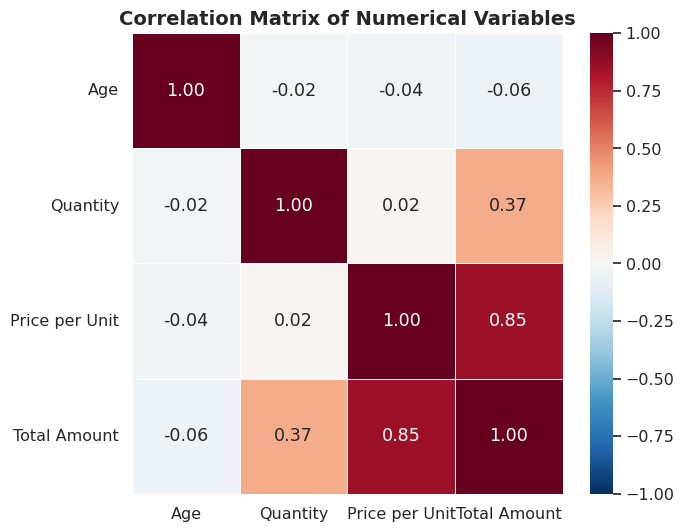

In [13]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, ax=ax)
ax.set_title("Correlation Matrix of Numerical Variables")
save("08_correlation_heatmap")

Price per Unit is strongly correlated with Total Amount (0.85), Quantity moderately (0.37). Age has almost no correlation with anything (between -0.02 and -0.06), so age alone does not predict spending.

## 7. Additional Insights

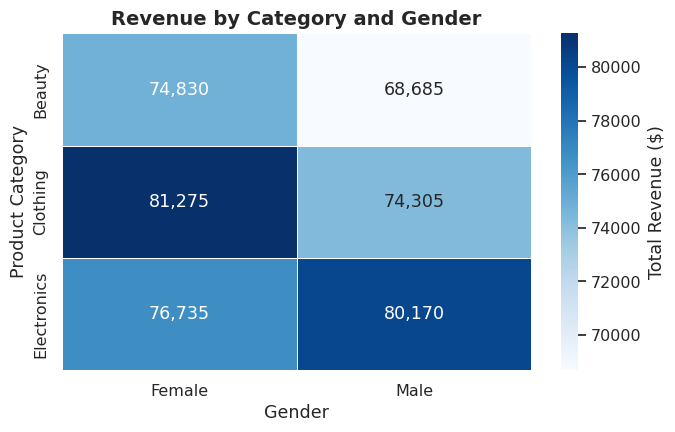

In [14]:
cg = df.pivot_table(index="Product Category", columns="Gender", values="Total Amount", aggfunc="sum")
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(cg, annot=True, fmt=",.0f", cmap="Blues", linewidths=.5, cbar_kws={"label": "Total Revenue ($)"}, ax=ax)
ax.set_title("Revenue by Category and Gender"); ax.set_xlabel("Gender"); ax.set_ylabel("Product Category")
save("09_category_by_gender")

Women spend more on Beauty (\$74,830 vs \$68,685) and Clothing (\$81,275 vs \$74,305); men lead in Electronics (\$80,170 vs \$76,735).

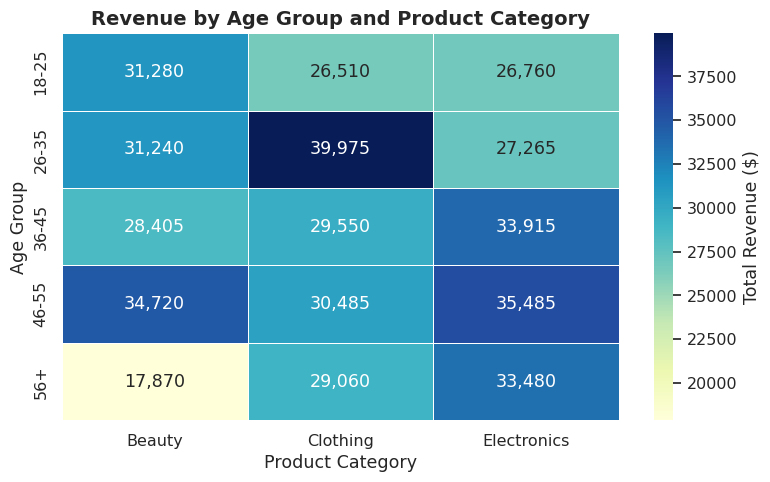

In [15]:
ac = df.pivot_table(index="Age Group", columns="Product Category", values="Total Amount", aggfunc="sum", observed=True)
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ac, annot=True, fmt=",.0f", cmap="YlGnBu", linewidths=.5, cbar_kws={"label": "Total Revenue ($)"}, ax=ax)
ax.set_title("Revenue by Age Group and Product Category"); ax.set_xlabel("Product Category"); ax.set_ylabel("Age Group")
save("10_age_group_by_category")

Beauty is weak among customers 56+ (\$17,870), about half of the 46-55 group (\$34,720). Ages 26-35 are the top Clothing buyers (\$39,975).

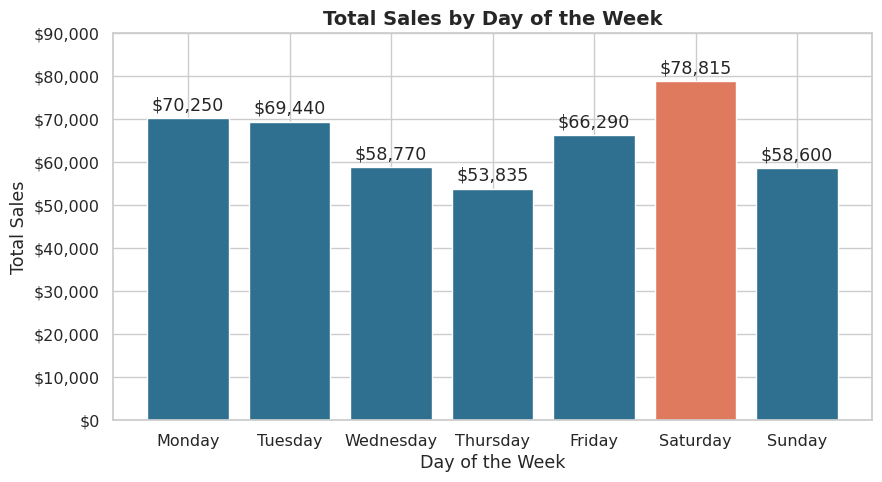

In [16]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df.groupby(df["Date"].dt.day_name())["Total Amount"].sum().reindex(order)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(dow.index, dow.values, color=[ACCENT if v == dow.max() else PRIMARY for v in dow.values])
ax.set_title("Total Sales by Day of the Week"); ax.set_xlabel("Day of the Week"); ax.set_ylabel("Total Sales")
ax.yaxis.set_major_formatter(money)
ax.bar_label(ax.containers[0], labels=[f"${v:,}" for v in dow.values], padding=3)
ax.set_ylim(0, 90000)
save("11_sales_by_weekday")

Saturday is the busiest day (\$78,815) and Thursday the quietest (\$53,835), about 46% lower.

In [17]:
qty = df.groupby("Quantity").agg(Transactions=("Transaction ID", "count"), Revenue=("Total Amount", "sum"))
qty["Revenue Share %"] = (qty["Revenue"] / qty["Revenue"].sum() * 100).round(1)
qty

,Transactions,Revenue,Revenue Share %
Quantity,,,
1,253,44805,9.8
2,243,81050,17.8
3,241,144285,31.6
4,263,185860,40.8


Baskets of 4 items are 26.3% of transactions but 40.8% of revenue (\$185,860).

## 8. Conclusion and Recommendations
1. **Push premium products:** \$300/\$500 items bring 88.4% of revenue from 39.6% of transactions. Use cheap items as add-ons.
2. **Encourage bigger baskets:** 4-item baskets give 40.8% of revenue. Offer multi-buy discounts.
3. **Fix the Q3 / September dip:** Q3 (\$96,045) trails Q4 (\$126,190) and September (\$23,620) is less than half of May. Plan a seasonal campaign.
4. **Plan for weekdays:** Saturday earns \$78,815 vs \$53,835 on Thursday. Stock for weekends and run mid-week offers.
5. **Target by segment:** Beauty and Clothing for women, Electronics for men, and a Beauty offer for customers 56+ (\$17,870).